# Prédiction du prix des véhicules automobiles

Ce projet explore un dataset de véhicules automobiles pour comprendre
quels facteurs influencent le prix de vente (MSRP).
Je compare deux approches de modélisation : la régression linéaire
et le Random Forest, pour voir laquelle prédit le mieux les prix.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
# Chargement du dataset.
df = pd.read_csv(r'C:\Users\~A.B.M.V~\Documents\Projet-Pr-diction-Prix-Voitures\data.csv')

print(f"{df.shape[0]:,} lignes, {df.shape[1]} variables")
df.head()

11,914 lignes, 16 variables


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


## Étape 1  Exploration des données

Avant de modéliser quoi que ce soit, je veux comprendre
la structure du dataset, les types de variables
et l'ampleur des valeurs manquantes.

In [3]:
# Types de variables et valeurs manquantes.
print(df.dtypes)
print()
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Valeurs manquantes :")
print((missing / len(df) * 100).round(2))

Make                     str
Model                    str
Year                   int64
Engine Fuel Type         str
Engine HP            float64
Engine Cylinders     float64
Transmission Type        str
Driven_Wheels            str
Number of Doors      float64
Market Category          str
Vehicle Size             str
Vehicle Style            str
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

Valeurs manquantes :
Market Category     31.41
Engine HP            0.58
Engine Cylinders     0.25
Number of Doors      0.05
Engine Fuel Type     0.03
dtype: float64


In [4]:
# Statistiques descriptives des variables numériques.
df.describe().round(2)

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.00,11845.00,11884.00,11908.00,11914.00,11914.00,11914.00,11914.00
mean,2010.38,249.39,5.63,3.44,26.64,19.73,1554.91,40594.74
std,7.58,109.19,1.78,0.88,8.86,8.99,1441.86,60109.10
min,1990.00,55.00,0.00,2.00,12.00,7.00,2.00,2000.00
25%,2007.00,170.00,4.00,2.00,22.00,16.00,549.00,21000.00
50%,2015.00,227.00,6.00,4.00,26.00,18.00,1385.00,29995.00
75%,2016.00,300.00,6.00,4.00,30.00,22.00,2009.00,42231.25
max,2017.00,1001.00,16.00,4.00,354.00,137.00,5657.00,2065902.00


FileNotFoundError: [Errno 2] No such file or directory: 'notebooks/distribution_prix.png'

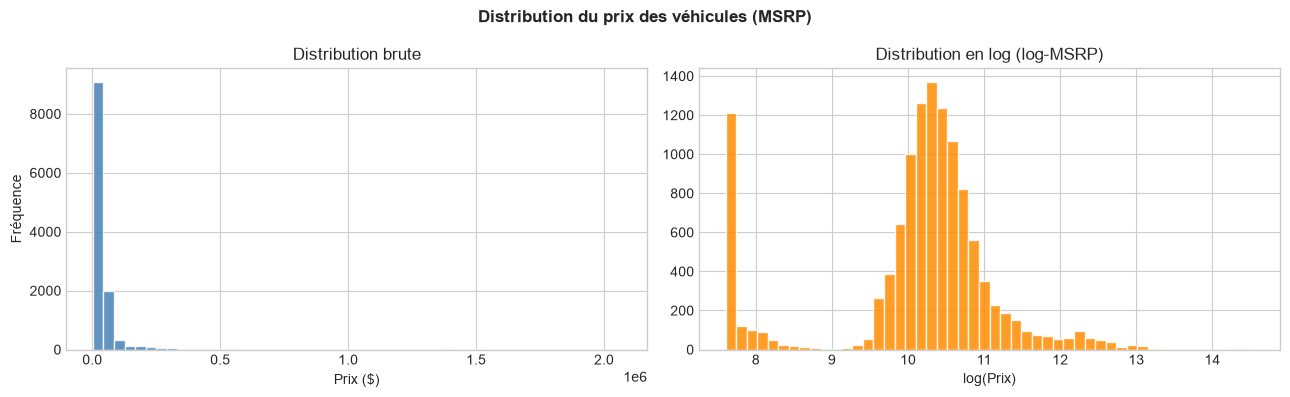

In [ ]:
# Distribution du prix cible (MSRP).
from pathlib import Path
Path('notebooks').mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Distribution du prix des véhicules (MSRP)', fontweight='bold')

axes[0].hist(df['MSRP'].dropna(), bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Distribution brute')
axes[0].set_xlabel('Prix ($)')
axes[0].set_ylabel('Fréquence')

axes[1].hist(np.log1p(df['MSRP'].dropna()), bins=50, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].set_title('Distribution en log (log-MSRP)')
axes[1].set_xlabel('log(Prix)')

plt.tight_layout()
plt.savefig('notebooks/distribution_prix.png', dpi=150, bbox_inches='tight')
plt.show()

La distribution du prix est très asymétrique vers la droite :
la grande majorité des véhicules sont dans la gamme abordable,
avec quelques modèles de luxe qui tirent la distribution vers le haut.
La transformation logarithmique donne une distribution beaucoup plus symétrique.

## Étape 2 Nettoyage des données

Je supprime la colonne Market Category qui contient
trop de valeurs manquantes et une cardinalité très élevée.
Je retire ensuite les doublons.

In [ ]:
# Suppression de Market Category et des doublons.
df = df.drop('Market Category', axis=1)
df = df.drop_duplicates()

print(f"Après nettoyage : {df.shape[0]:,} lignes, {df.shape[1]} variables")

In [ ]:
# Traitement des outliers sur le prix via la méthode IQR.
# Je ne supprime que les outliers extrêmes sur la variable cible.
Q1  = df['MSRP'].quantile(0.25)
Q3  = df['MSRP'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[(df['MSRP'] >= lower) & (df['MSRP'] <= upper)].copy()

print(f"Avant  : {df.shape[0]:,} lignes")
print(f"Après  : {df_clean.shape[0]:,} lignes")
print(f"Seuils : {lower:.0f}$ — {upper:.0f}$")

## Étape 3  Analyse exploratoire

Je regarde maintenant quelles variables sont les plus
corrélées avec le prix, pour guider le choix des features.

In [ ]:
# Corrélations avec le prix.
numeric_cols  = df_clean.select_dtypes(include='number').columns
correlations  = df_clean[numeric_cols].corr()['MSRP'].drop('MSRP').sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['tomato' if x < 0 else 'steelblue' for x in correlations]
correlations.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Corrélation des variables numériques avec le prix (MSRP)', fontweight='bold')
ax.set_xlabel('Coefficient de corrélation')

plt.tight_layout()
plt.savefig('notebooks/correlations.png', dpi=150, bbox_inches='tight')
plt.show()

print(correlations.round(3))

In [ ]:
# Répartition des variables catégorielles clés.
cat_cols = ['Engine Fuel Type', 'Transmission Type', 'Driven_Wheels', 'Vehicle Size']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Répartition des variables catégorielles', fontweight='bold')
axes = axes.ravel()

for ax, col in zip(axes, cat_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(y=df_clean[col], order=order, ax=ax, color='steelblue')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('Nombre de véhicules')
    ax.set_ylabel('')

plt.tight_layout()
plt.savefig('notebooks/variables_categorielles.png', dpi=150, bbox_inches='tight')
plt.show()

La puissance moteur (Engine HP) est la variable numérique
la plus corrélée avec le prix. Le nombre de cylindres suit.
La consommation (highway MPG, city MPG) est corrélée négativement :
les voitures plus puissantes consomment plus et coûtent plus cher.

Du côté catégoriel, l'automatique domine largement,
et les tailles Midsize et Compact sont les plus fréquentes.

## Étape 4  Préparation des données

Je sépare d'abord le train et le test,
puis j'applique le prétraitement uniquement sur le train
pour éviter toute fuite de données vers le test.

In [ ]:
# Séparation features / cible.
TARGET = 'MSRP'

X = df_clean.drop(TARGET, axis=1)
y = df_clean[TARGET]

# Séparation train / test — toujours avant le prétraitement.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train : {X_train.shape[0]:,} lignes")
print(f"Test  : {X_test.shape[0]:,} lignes")

In [ ]:
# Identification des colonnes numériques et catégorielles.
num_features = X_train.select_dtypes(include='number').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

print(f"Variables numériques   : {num_features}")
print(f"Variables catégorielles: {cat_features}")

In [ ]:
# Pipeline de prétraitement.
# Numériques : imputation par la médiane + standardisation.
# Catégorielles : imputation par la valeur la plus fréquente + encodage ordinal.
# Tout est appris sur le train uniquement — pas de fuite de données.

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features),
])

## Étape 5  Modélisation

Je compare deux modèles :
une régression linéaire (modèle de référence simple)
et un Random Forest (modèle plus flexible, non linéaire).
Les deux sont entraînés dans un pipeline pour garantir
que le prétraitement est toujours cohérent.

In [ ]:
# Entraînement des deux modèles.
pipe_lr = Pipeline([
    ('prep',  preprocessor),
    ('model', LinearRegression()),
])

pipe_rf = Pipeline([
    ('prep',  preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
])

pipe_lr.fit(X_train, y_train)
pipe_rf.fit(X_train, y_train)

print("Modèles entraînés.")

In [ ]:
# Prédictions et métriques sur le test.
y_pred_lr = pipe_lr.predict(X_test)
y_pred_rf = pipe_rf.predict(X_test)

def evaluate(name, y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name}")
    print(f"  R²   : {r2:.3f}")
    print(f"  MAE  : ${mae:,.0f}")
    print(f"  RMSE : ${rmse:,.0f}")
    print()
    return r2, mae, rmse

r2_lr, mae_lr, rmse_lr = evaluate("Régression Linéaire", y_test, y_pred_lr)
r2_rf, mae_rf, rmse_rf = evaluate("Random Forest",       y_test, y_pred_rf)

## Étape 6  Évaluation et visualisation

In [ ]:
# Prédit vs réel pour les deux modèles.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Prix prédit vs prix réel', fontweight='bold')

for ax, name, y_pred, color in zip(
    axes,
    ['Régression Linéaire', 'Random Forest'],
    [y_pred_lr, y_pred_rf],
    ['steelblue', 'darkorange']
):
    ax.scatter(y_test, y_pred, alpha=0.25, s=8, color=color)
    mv = max(y_test.max(), y_pred.max())
    ax.plot([0, mv], [0, mv], 'r--', linewidth=1.5, label='Prédiction parfaite')
    ax.set_xlabel('Prix réel ($)')
    ax.set_ylabel('Prix prédit ($)')
    ax.set_title(name, fontweight='bold')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('notebooks/predit_vs_reel.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Résidus du Random Forest.
residus = y_test.values - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Analyse des résidus — Random Forest', fontweight='bold')

axes[0].scatter(y_pred_rf, residus, alpha=0.25, s=8, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Prix prédit ($)')
axes[0].set_ylabel('Résidus ($)')
axes[0].set_title('Résidus vs valeurs prédites')

axes[1].hist(residus, bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Résidus ($)')
axes[1].set_ylabel('Fréquence')
axes[1].set_title('Distribution des résidus')

plt.tight_layout()
plt.savefig('notebooks/residus.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Importance des variables — Random Forest.
importances = pipe_rf.named_steps['model'].feature_importances_
feature_names = num_features + cat_features

imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
imp_series.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.invert_yaxis()
ax.set_title('Importance des variables — Random Forest', fontweight='bold')
ax.set_xlabel('Importance (Gini)')

plt.tight_layout()
plt.savefig('notebooks/importance_variables.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusion

Le Random Forest surpasse nettement la régression linéaire
sur ce problème, ce qui suggère que la relation entre
les caractéristiques du véhicule et son prix n'est pas linéaire.

Les variables les plus importantes pour la prédiction sont
la puissance moteur et le nombre de cylindres,
ce qui est cohérent avec ce qu'on observait dans la matrice de corrélation.

Les résidus sont globalement centrés autour de zéro,
avec quelques erreurs plus élevées sur les véhicules haut de gamme
qui restent difficiles à modéliser avec les seules caractéristiques techniques.

Ce projet m'a permis de comprendre l'importance de séparer
les données avant tout prétraitement, et d'utiliser des pipelines
pour garantir la cohérence entre entraînement et test.